# Part 3 – Estimating the washing machine from the whole-house meter

A smart meter only sees the **total** power of a home. Can we estimate the **washing machine** from it?
In REFIT we know both, so we can train a model on some homes and test it on a home it has never seen.

Data: the 1-minute data of homes 1, 2, 5, 7, 8, 9 saved in Part 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, precision_score, recall_score, f1_score

plt.rcParams["figure.figsize"] = (12, 4)
houses = pd.read_pickle("../data/houses_1min.pkl")
HOUSES = list(houses)

## 1. Features

To guess the washing machine at minute *t*, the model looks at the **whole-house power from 15 minutes
before to 15 minutes after** (idea from the Seq2Point paper, Zhang et al. 2018). One number alone can't
tell a kettle from a washing machine, but the shape over half an hour can: a kettle is ~3 kW for 3 minutes,
a washing machine heater ~2 kW for 15–20 minutes.

Extra features: mean / std / max / min of that window, power above the home's base load, hour and weekday.

In [2]:
def make_features(df):
    agg = df["aggregate"]
    f = {}
    for k in range(-15, 16):
        f[f"agg_{k:+d}"] = agg.shift(-k)                  # whole-house power k minutes away
    window = agg.rolling(31, center=True, min_periods=1)
    f["win_mean"] = window.mean()
    f["win_std"] = window.std()
    f["win_max"] = window.max()
    f["win_min"] = window.min()
    f["above_base"] = agg - agg.rolling(61, center=True, min_periods=1).min()
    local = df.index.tz_convert("Europe/London")
    f["hour"] = local.hour
    f["weekday"] = local.day_of_week
    return pd.DataFrame(f, index=df.index)


data = {}
for h in HOUSES:
    X = make_features(houses[h])
    X["wm"] = houses[h]["wm"]                               # the target
    data[h] = X.dropna().astype("float32")                  # only minutes where everything is known
    print("House", h, ":", len(data[h]), "minutes")

FEATURES = [c for c in data[HOUSES[0]].columns if c != "wm"]
data[2].head()

House 1 : 789647 minutes
House 2 : 654110 minutes


House 5 : 813637 minutes
House 7 : 763262 minutes


House 8 : 705058 minutes
House 9 : 651514 minutes


,agg_-15,agg_-14,agg_-13,agg_-12,agg_-11,agg_-10,agg_-9,agg_-8,agg_-7,agg_-6,...,agg_+14,agg_+15,win_mean,win_std,win_max,win_min,above_base,hour,weekday,wm
time,,,,,,,,,,,,,,,,,,,,,
2013-09-17 22:23:00+00:00,697.571411,650.799988,813.900024,743.000000,688.625000,693.428589,690.599976,689.454529,688.000000,682.799988,...,102.599998,76.800003,436.367798,297.499329,813.900024,76.800003,351.463623,23.0,1.0,0.0
2013-09-17 22:24:00+00:00,650.799988,813.900024,743.000000,688.625000,693.428589,690.599976,689.454529,688.000000,682.799988,730.454529,...,76.800003,60.500000,415.817108,300.839508,813.900024,60.500000,269.263641,23.0,1.0,0.0
2013-09-17 22:25:00+00:00,813.900024,743.000000,688.625000,693.428589,690.599976,689.454529,688.000000,682.799988,730.454529,812.000000,...,60.500000,59.636364,396.747314,304.165894,813.900024,59.636364,123.454544,23.0,1.0,0.0
2013-09-17 22:26:00+00:00,743.000000,688.625000,693.428589,690.599976,689.454529,688.000000,682.799988,730.454529,812.000000,808.909119,...,59.636364,59.777779,372.420776,299.816254,812.000000,59.636364,127.474747,23.0,1.0,0.0
2013-09-17 22:27:00+00:00,688.625000,693.428589,690.599976,689.454529,688.000000,682.799988,730.454529,812.000000,808.909119,808.099976,...,59.777779,59.900002,350.385315,296.759247,812.000000,59.636364,127.363640,23.0,1.0,0.0


## 2. Models

| Model | Idea |
|---|---|
| **Always off** | predicts 0 W every minute (baseline) |
| **Usage profile** | average washing-machine power for that weekday and hour in the training homes (baseline) |
| **Linear regression** | a weighted sum of the features |
| **Random forest** | many decision trees, each trained on random data, answers averaged |

After predicting, negative values become 0 and values below 20 W become 0 (the same "off" threshold as Part 2).

## 3. Train / test split: leave one house out

We do **not** split minutes randomly: minute 10:31 and 10:32 of the same wash are almost identical, so a
random split would put one in training and one in testing and the model would just remember it
(**data leakage**). Instead we train on 5 homes and test on the 6th, and repeat so every home is tested once.
This is also the real question: *does it work for a new customer's home?*

## 4. Metrics

- **MAE**: average error in W per minute.
- **Precision / recall / F1** on "on" minutes (> 20 W): does it find the washes (recall), without false alarms (precision)?
- **Energy error %**: is the total washing-machine energy right?

In [3]:
def score(y, p):
    on, pred_on = y > 20, p > 20
    return {"MAE (W)": mean_absolute_error(y, p),
            "precision": precision_score(on, pred_on, zero_division=0),
            "recall": recall_score(on, pred_on),
            "F1": f1_score(on, pred_on),
            "energy error %": 100 * (p.sum() - y.sum()) / y.sum()}


def clean_prediction(p):
    p = np.clip(p, 0, None)
    p[p < 20] = 0
    return p

## 5. Run the leave-one-house-out loop (takes a few minutes)

In [4]:
results = []
predictions = {}
importances = []

for test in HOUSES:
    train_all = pd.concat([data[h] for h in HOUSES if h != test])
    train = train_all.sample(n=400_000, random_state=42)        # random sample to keep training fast
    test_df = data[test]
    y = test_df["wm"].to_numpy()

    # baseline 2: average power by weekday and hour in the training homes
    profile = train_all.groupby(["weekday", "hour"])["wm"].mean()
    profile_pred = profile.reindex(pd.MultiIndex.from_frame(test_df[["weekday", "hour"]])).fillna(0).to_numpy()

    lr = LinearRegression().fit(train[FEATURES], train["wm"])
    rf = RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_leaf=20, n_jobs=-1, random_state=42)
    rf.fit(train[FEATURES], train["wm"])
    importances.append(rf.feature_importances_)

    preds = {"always off": np.zeros_like(y),
             "usage profile": profile_pred,
             "linear regression": clean_prediction(lr.predict(test_df[FEATURES])),
             "random forest": clean_prediction(rf.predict(test_df[FEATURES]))}
    predictions[test] = pd.DataFrame(preds, index=test_df.index).assign(actual=y, aggregate=test_df["agg_+0"].to_numpy())

    for name, p in preds.items():
        results.append({"test house": test, "model": name, **score(y, p)})
    print("House", test, "done")

results = pd.DataFrame(results)

House 1 done


House 2 done


House 5 done


House 7 done


House 8 done


House 9 done


In [5]:
# average over the 6 test homes
results.drop(columns="test house").groupby("model", sort=False).mean().round(2)

,MAE (W),precision,recall,F1,energy error %
model,,,,,
always off,22.36,0.00,0.00,0.00,-100.00
usage profile,42.09,0.06,0.51,0.10,24.14
linear regression,38.08,0.15,0.77,0.24,14.22
random forest,34.43,0.19,0.67,0.29,14.45


**Reading the averages**
- **Always off** has the *lowest* MAE (22 W) but finds **no** washes. The washing machine is off ~95 % of the time,
  so MAE alone is misleading here. That is why we also look at F1 and energy.
- **Usage profile** knows *when* people usually wash, but not *whether* they washed today: F1 only 0.10.
- **Linear regression** finds the most "on" minutes (recall 0.77) but raises many false alarms (precision 0.15).
- **Random forest** has the best F1 (**0.29**), the best precision (**0.19**) and the lowest MAE of the real models.
  It finds about **2 out of 3** washing minutes, but only about **1 in 5** of its "on" predictions is right:
  false alarms are the main weakness.
- Energy: the averages (+14 %) hide big differences per home (see the per-home table: from −25 % to +64 % for the
  random forest), so the energy estimate is only rough.

In [6]:
results.round(2)

,test house,model,MAE (W),precision,recall,F1,energy error %
0,1,always off,10.23,0.00,0.00,0.00,-100.00
1,1,usage profile,34.38,0.02,0.53,0.04,145.98
2,1,linear regression,22.65,0.09,0.86,0.16,44.91
3,1,random forest,23.51,0.11,0.74,0.19,63.99
4,2,always off,18.21,0.00,0.00,0.00,-100.00
5,2,usage profile,39.05,0.05,0.46,0.10,27.89
6,2,linear regression,32.31,0.14,0.43,0.21,4.18
7,2,random forest,26.09,0.18,0.36,0.24,-25.41
8,5,always off,22.20,0.00,0.00,0.00,-100.00
9,5,usage profile,39.21,0.08,0.65,0.15,1.27


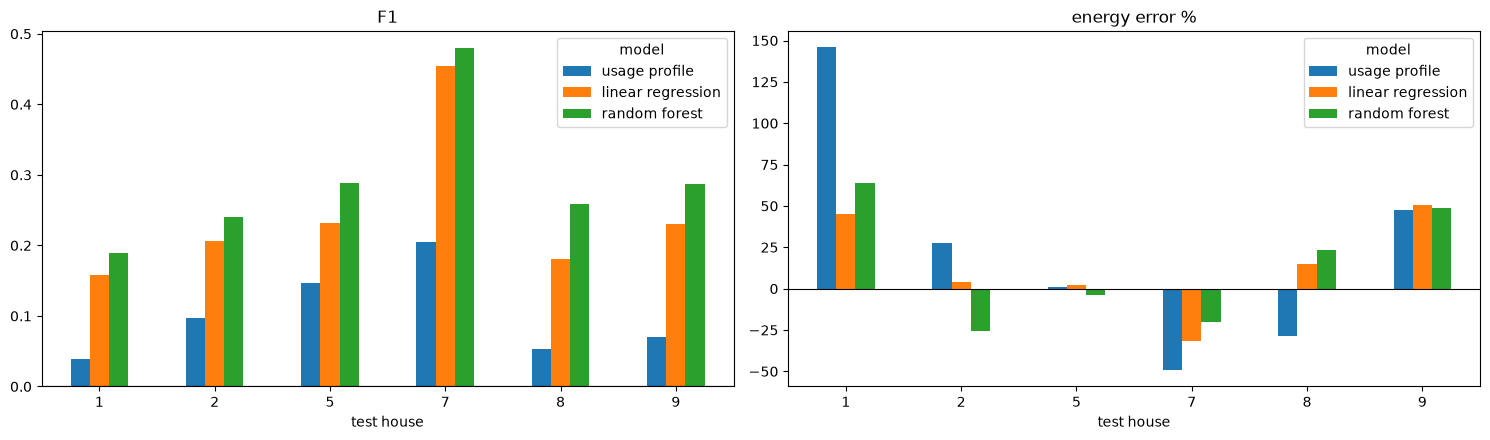

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["F1", "energy error %"]):
    results[results["model"] != "always off"].pivot(index="test house", columns="model", values=metric)[
        ["usage profile", "linear regression", "random forest"]].plot.bar(ax=ax, rot=0)
    ax.set_title(metric); ax.axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.savefig("../figures/part3_per_house.png", dpi=110); plt.show()

- The random forest beats the usage profile in **every** home and beats linear regression on F1 in every home.
- Results differ a lot by home: **House 7** is easiest (F1 0.48, it washes almost 10 times a week),
  **House 1** the hardest (0.19). Houses 1, 8 and 9 also own a **washer-dryer**, which looks like a washing
  machine in the whole-house signal and pushes the energy estimate up (+64 %, +24 %, +49 %).

## 6. Actual vs predicted (House 2, never seen in training)

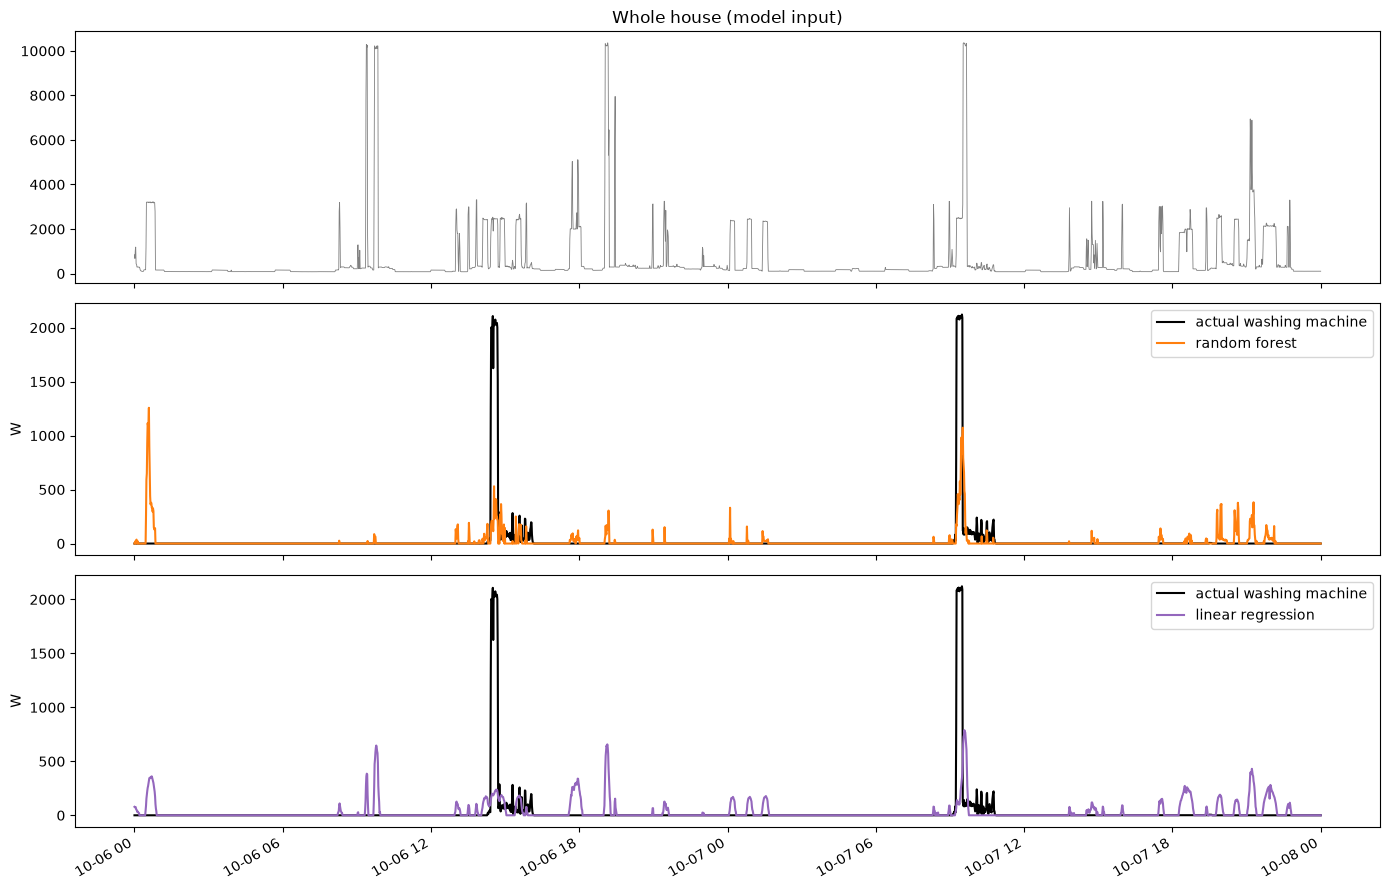

In [8]:
p = predictions[2].tz_convert("Europe/London")
daily = p["actual"].resample("1D").sum() / 60 / 1000
busy = daily[daily > 0.3]
start = busy.index[(busy - busy.median()).abs().argmin()]          # a typical washing day
w = p.loc[start:start + pd.Timedelta("2D")]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(w["aggregate"], color="grey", lw=0.6); axes[0].set_title("Whole house (model input)")
for ax, model, color in zip(axes[1:], ["random forest", "linear regression"], ["tab:orange", "tab:purple"]):
    ax.plot(w["actual"], color="black", label="actual washing machine")
    ax.plot(w[model], color=color, label=model)
    ax.set_ylabel("W"); ax.legend(loc="upper right")
fig.autofmt_xdate(); plt.tight_layout(); plt.savefig("../figures/part3_actual_vs_predicted.png", dpi=110); plt.show()

Both washes are found **at the right time** by both models, but the predicted power is too low: the random forest
predicts ~500–1,000 W where the real heating block is ~2,000 W. The same kind of 2 kW block also comes from other
appliances, so when the model is unsure it predicts something **in between**.

Linear regression shows the problem with a straight-line model: it reacts to *every* rise in power with a smooth bump
(many small false alarms through the evening), because it can only add up the inputs. It cannot recognise the
*shape* of a 2 kW block that lasts 15 minutes. Trees can learn rules like "high, flat, for 15 minutes", which is
why the random forest is cleaner.

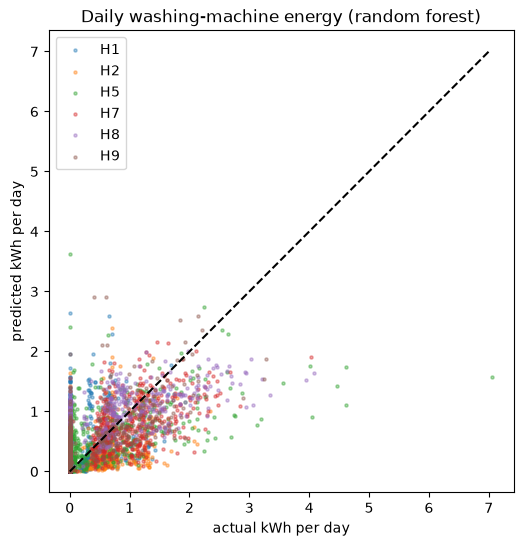

In [9]:
# daily energy: actual vs random forest, every test home
for h in HOUSES:
    d = predictions[h][["actual", "random forest"]].resample("1D").sum() / 60 / 1000
    plt.scatter(d["actual"], d["random forest"], s=5, alpha=0.4, label=f"H{h}")
plt.plot([0, 7], [0, 7], "k--")
plt.xlabel("actual kWh per day"); plt.ylabel("predicted kWh per day"); plt.legend()
plt.title("Daily washing-machine energy (random forest)")
plt.gcf().set_size_inches(6, 6); plt.savefig("../figures/part3_daily_energy.png", dpi=110); plt.show()

Each dot is one day in one test home; on the dashed line the prediction would be perfect. There is a clear trend
(more real washing → more predicted), but with a lot of scatter: busy days are under-estimated and days without any
wash often get a small amount. Daily or monthly totals are more reliable than single minutes.

## 7. What does the random forest look at? (feature importance)

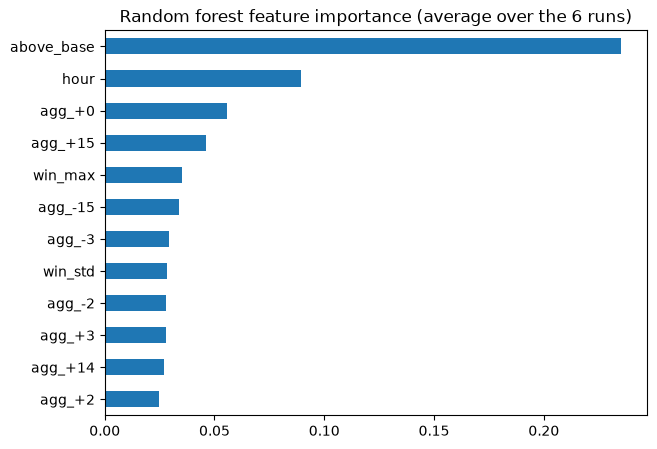

In [10]:
imp = pd.Series(np.mean(importances, axis=0), index=FEATURES).sort_values()
imp.tail(12).plot.barh(figsize=(7, 5))
plt.title("Random forest feature importance (average over the 6 runs)"); plt.show()

- **`above_base`** (power above the home's normal base load) is by far the most important: a washing machine adds
  ~2 kW on top of what is normally running.
- **`hour`** is second: people wash at typical times (mostly mornings).
- Then the power **now** (`agg_+0`) and **15 minutes before and after** (`agg_-15`, `agg_+15`): this tells whether a
  high power level lasts long (washing machine heater) or is short (kettle).

## 8. Failure cases

The day with the biggest over-prediction (false alarm) and the biggest under-prediction (miss).

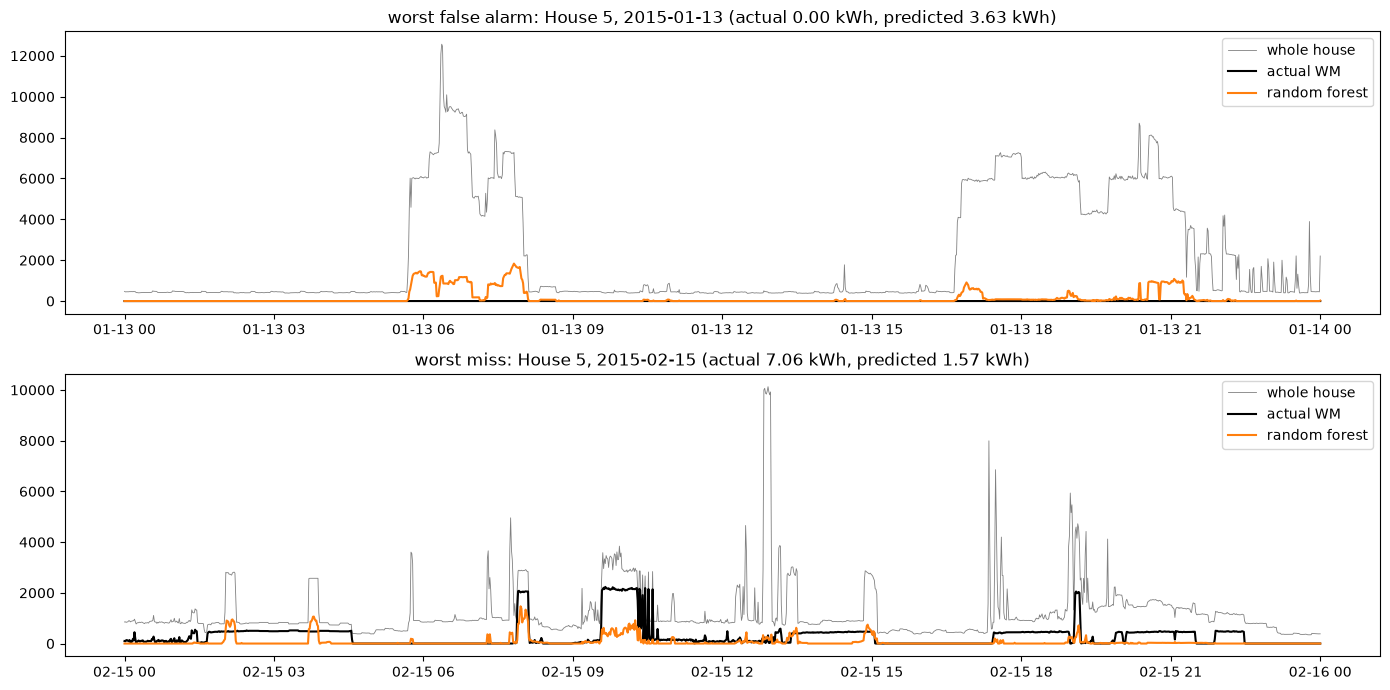

In [11]:
days = []
for h in HOUSES:
    d = predictions[h][["actual", "random forest"]].resample("1D").sum() / 60 / 1000
    days.append(d.assign(house=h))
days = pd.concat(days).rename_axis("day").reset_index()
days["error"] = days["random forest"] - days["actual"]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (title, row) in zip(axes, [("worst false alarm", days.loc[days["error"].idxmax()]),
                                    ("worst miss", days.loc[days["error"].idxmin()])]):
    p = predictions[int(row["house"])].loc[row["day"]:row["day"] + pd.Timedelta("1D")]
    ax.plot(p["aggregate"], color="grey", lw=0.6, label="whole house")
    ax.plot(p["actual"], color="black", label="actual WM")
    ax.plot(p["random forest"], color="tab:orange", label="random forest")
    ax.set_title(f"{title}: House {int(row['house'])}, {row['day']:%Y-%m-%d} "
                 f"(actual {row['actual']:.2f} kWh, predicted {row['random forest']:.2f} kWh)")
    ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig("../figures/part3_failure_cases.png", dpi=110); plt.show()

1. **Worst false alarm – House 5, 13 Jan 2015** (predicted 3.6 kWh, real 0): the house uses **6–12 kW for hours**,
   most likely electric heating on a cold winter day. Nothing like it was in the training homes, so the model calls
   part of it washing. Other **look-alikes** are kettles, dishwashers, tumble dryers and washer-dryers, which all
   have ~2 kW heaters.
2. **Worst miss – House 5, 15 Feb 2015** (real 7.1 kWh, predicted 1.6): the machine runs many times, often at only
   **~480 W for hours with no heating block** (cold/eco programmes, or something else plugged into that socket).
   Without the 2 kW heater there is almost nothing to see in the whole-house signal. The one long heating block
   overlapped with another ~1.5 kW load, so it was only partly found.

**The model will also struggle** in homes very different from the 5 training homes, during missing or frozen data,
and in real time (it needs 15 minutes of "future" data).

## Summary of Part 3

- The random forest finds about **2/3 of washing-machine minutes** in a home it has never seen (F1 0.29, about 3x the
  usage-profile baseline), using only the whole-house meter.
- It is **not reliable for single washes**: many false alarms, and it under-estimates the power of each wash.
- It is useful for **rough insights over weeks or months**, or across many homes, not for exact per-appliance billing.
- An earlier test with gradient boosting (F1 0.29) and a small neural network (F1 0.25) did not do better, so the
  simpler random forest was kept.